# Lab 1: Deep Learning basics with PyTorch

Authors: Alexandre Bruckert, Nantes Université

Sourced from https://docs.pytorch.org/tutorials/beginner/basics/intro.html

Date: 2026/2027

The aim of this lab is to introduce a full pipeline of a deep learning model, from data to prediction and evaluation.

Associated with this lab is a learning sheet. For each notion on this sheet, you must find a definition and explore its effects during this lab. You help yourself with the PyTorch documentation, the course slides, and any other reliable source.

## Part 1: Basics: Tensors and autograd

The main data structure that we manipulate in PyTorch is the **tensor**. It is a generalization of matrices to higher dimensions. Tensors can be created from Python lists, Numpy arrays, or pre-filled with zeros or random values.

In [1]:
import torch
import numpy as np

print("--- 1. Creating tensors ---")
# From a Python list
t1 = torch.tensor([[1, 2], [3, 4]], dtype=torch.float32)
print("Tensor from list :\n", t1)

# Empty tensor
t_empty = torch.empty(2, 3)
print(f"Empty tensor :\n", t_empty)
# You should see some random values; the torch.empty() function allocates memory for the tensor, but does not initialize it.
# What you are seeing is whatever was in the memory at this time.

# Pre-filled tensors
t_zeros = torch.zeros(2, 3)
t_rand = torch.randn(3, 3) # Gaussian distribution (mean 0, std 1)
print(f"Shape of t_rand : {t_rand.shape}")

# Bridging with Numpy arrays (very useful for visualization with matplotlib or any other visualization library)
np_array = np.array([1, 2, 3])
t_from_np = torch.from_numpy(np_array)
back_to_np = t_from_np.numpy()


print("\n--- 2. Manipulating and reshaping tensors ---")
# In a neural network, one often needs to flatten images.
# The .view() function (or .reshape()) is the main tool for that.
image_ex = torch.randn(1, 28, 28) # Random grayscale image; dimensions are (channel, height, width)
print(f"Original shape : {image_ex.shape}")

# Dimensions 1 and 2 can be flattened into a single one, while keeping the channel dimension (1)
image_flatten = image_ex.view(1, -1)
# The arguments of view should be the dimension of the new tensor; -1 means "whatever is left".
print(f"Size after flatten : {image_flatten.shape}") # Should give [1, 784], because 28*28 = 784


print("\n--- 3. Autograd ---")
# PyTorch main asset is its ability to automatically compute gradients.
# This is at the core of the backpropagation algorithms.

# Let us take an easy function : f(x) = 3x^2 + 4x + 2
# Gradient should be f'(x) = 6x + 4.
# If x = 2.0, then f'(2) = 16. Let's check it!

# We create a tensor x with requires_grad=True, so that PyTorch will compute the gradient.
x = torch.tensor([2.0], requires_grad=True)

# Definition of the function (Forward pass)
y = 3*x**2 + 4*x + 2
print(f"y(2) : {y.item()}")

# Automated gradient computation (Backward pass)
y.backward()

print(f"Gradient dy/dx at x=2 : {x.grad.item()} (Should be: 16.0)")

# Warning: In Pytorch, gradients accumulate!
# In a real training loop, gradients should be reset to zero at each iteration.
# optimizer.zero_grad() should be called at the beginning of each iteration to do so.

--- 1. Creating tensors ---
Tensor from list :
 tensor([[1., 2.],
        [3., 4.]])
Empty tensor :
 tensor([[2.7001e+36, 1.0524e-42, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00]])
Shape of t_rand : torch.Size([3, 3])

--- 2. Manipulating and reshaping tensors ---
Original shape : torch.Size([1, 28, 28])
Size after flatten : torch.Size([1, 784])

--- 3. Autograd ---
y(2) : 22.0
Gradient dy/dx at x=2 : 16.0 (Should be: 16.0)


## Part 2: Data Pipeline

In deep learning, data management is (at least!) as important as the architecture of the model.
We can't generally load all of our datasets into whatever memory is available at once.
PyTorch provides two very powerful tools for that :

- Datasets: They are the main data structure in PyTorch. They contain the data and the labels.
- DataLoaders: They are the main tool for iterating over the data. They can be used to shuffle, batch, and split the data.

Basically, a PyTorch dataset is a storing structure, containing samples and labels, and Dataloaders are wrapping an iterable around it, to enable easy access to the samples.

In this lab, we will use the FashionMNIST dataset, which contains 70 000 grayscale images of clothing items (28x28 pixels). We will split it into three subsets:
- Train: For adjusting the weights of the model.
- Validation: To evaluate the model during training, tune the hyperparameters (tuning) and detect overfitting.
- Test: The final evaluation, invisible to the model until the end.

0.1%

--- 1. Downloading and transforming the dataset ---


100.0%
100.0%
100.0%
100.0%


Size of the raw training set : 60000 images

--- 2. Train/validation split ---

--- 3. Creating DataLoaders ---

--- 4. Batch Visualization ---
Shape of an image batch : torch.Size([64, 1, 28, 28])


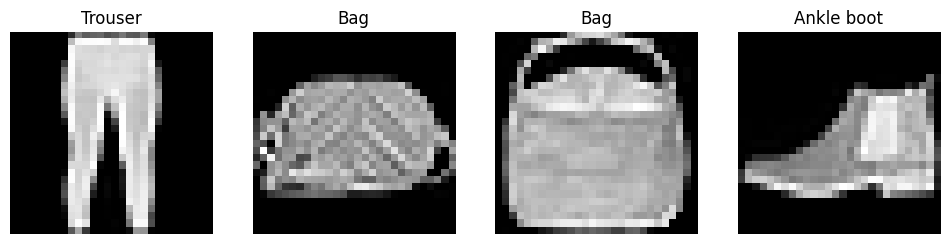

In [2]:
import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt

print("--- 1. Downloading and transforming the dataset ---")

# Raw images are in PIL format (pixels of 0 to 255).
# PyTorch needs tensors, which use values from 0 to 1.
# Usually, a common preprocessing is to normalize the pixel values to have a mean of 0.5 and a standard deviation of 0.5.
# To do so, the transform function is used. We can stack several transformations together with transforms.Compose()
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Dowloading the dataset
# train=True will download the training set, composed of 60k images, and train=False will download the test set.
raw_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

print(f"Size of the raw training set : {len(raw_dataset)} images")


print("\n--- 2. Train/validation split ---")
generator = torch.Generator().manual_seed(123)

# TODO : Divide raw_dataset into train_dataset (80%) and val_dataset (20%)
# train_dataset, val_dataset = ...
#print(f"Train : {len(train_dataset)} | Val : {len(val_dataset)} | Test : {len(test_dataset)}")
train_dataset, val_dataset = random_split(raw_dataset, [0.8, 0.2], generator=generator)

print("\n--- 3. Creating DataLoaders ---")
# The batch_size is a hyperparameter that controls the size of the batches (i.e. how many images are fed to the model at each iteration).
batch_size = 64

# TODO : Create the corresponding DataLoaders.
# IMPORTANT : it is particularly important to shuffle (arg. shuffle=True) the train_loader
# in order to avoid having the model memorizing the order of the images.
# This is not necessary for the validation and test loaders.
# train_loader = ...
# val_loader = ...
# test_loader = ...
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("\n--- 4. Batch Visualization ---")
# We extract a single batch of images and labels from the dataloader, to check that everything works.
images, labels = next(iter(train_loader))
print(f"Shape of an image batch : {images.shape}")
# This should be : [64, 1, 28, 28]
# The first dimension is the batch size, the second is the channel (1 for grayscale images), the third is the height and the fourth is the width.

# List of class names, for visualization purposes. The labels are integers from 0 to 9, corresponding to these classes.
classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    # In order to display the images with matplotlib, we need to convert them to numpy arrays and remove the channel dimension (1).
    img = images[i].squeeze().numpy()
    # If the image was normalized in [-1,1], we need to un-normalize it to [0,1].
    # img = (img * 0.5) + 0.5

    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(classes[labels[i].item()])
    axes[i].axis('off')
plt.show()

## Part 3: Model definition

Building a neural network in PyTorch is done by creating a Python class that inherits from nn.Module. To define a model, you must implement two essential methods:

- ```__init__(self)```: This is the constructor. Here, you define the "building blocks" of your network, such as the layers (nn.Linear), activation functions (nn.ReLU), and dropout.

-```forward(self, x)```: This defines the forward pass—how the input data x flows through the layers you defined in the constructor to produce the final predictions.

In the next cell, you will define a simple Multi-Layer Perceptron (MLP) model for classifying the FashionMNIST images. Since our FashionMNIST images are 28x28 pixels, the input to the network must be a 1D array of 784 pixels. You will need to "flatten" the 2D images before passing them through the fully connected layers. To make this template reusable, design the architecture dynamically using a list of hidden layer sizes and nn.Sequential.

In [5]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, input_size=784, hidden_sizes=[256, 128], num_classes=10, dropout_rate=0.0):
        """
        A feedforward Multilayer Perceptron (MLP) neural network class designed for dynamic
        construction of hidden layers and an output layer.

        :param input_size: (int) The size of the input feature vector.
        :param hidden_sizes: (list[int]) A list of integers representing the number of neurons for each hidden layer.
        :param num_classes: (int) The number of output classes for the final classification layer.
        :param dropout_rate: (float) The probability of dropping neurons in the dropout layer (if used).
        """
        super(MLP, self).__init__()

        layers = []
        in_features = input_size

        # TODO: Build the hidden layers dynamically based on the 'hidden_sizes' list.
        # For each number of neurons in hidden_sizes:
        # 1. Add a Fully Connected layer (nn.Linear)
        # 2. Add an Activation function (nn.ReLU)
        # 3. (For later) Add Dropout (nn.Dropout), BatchNormalization, etc.
        for h in hidden_sizes:
            layers.append(nn.Linear(in_features, h))# 1. Add a Fully Connected layer (nn.Linear)
            layers.append(nn.ReLU())#2. Add an Activation function (nn.ReLU)
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))# 3. (For later) Add Dropout (nn.Dropout), BatchNormalization, etc.
            in_features = h

        # TODO: Add the final output layer (nn.Linear).
        # Note: Do not add an activation function here! The CrossEntropyLoss handles the Softmax internally.
        # layers.append(...)
        layers.append(nn.Linear(in_features, num_classes))

        # nn.Sequential packs our list of layers into a singl+e module
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        """
        Processes the input tensor through the feedforward operation of the module.

        :param x: (torch.Tensor) 4D input tensor with shape [batch_size, channels, height, width]

        :return: (torch.Tensor) 2D tensor representing the output of the neural network.
        """

        # An MLP only accepts 1D vectors for each sample in the batch.
        # TODO: Flatten the spatial dimensions of x.
        # You want the shape to become [batch_size, 784]
        # x = ...
        x = x.view(x.size(0), -1)

        # TODO: Pass the flattened tensor through the network
        # out = ...
        out = self.network(x)

        return out

In [6]:
model = MLP()
print(model)

out = model(images)
print(out.shape)
print(out[0])

print(sum(p.numel() for p in model.parameters()))

MLP(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
torch.Size([64, 10])
tensor([-0.0224, -0.0485,  0.1473, -0.0214, -0.0749, -0.0153, -0.0954, -0.0571,
        -0.0648,  0.0431], grad_fn=<SelectBackward0>)
235146


In [7]:
import torch.optim as optim

# Good practice: Code should be agnostic to the device (allows for CPU, CUDA, or MPS usage).
# We will use the device variable to move our model and data to the appropriate device.
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device : {device}")

def train_epoch(model, dataloader, criterion, optimizer, device):
    """
    Trains a PyTorch model for one complete epoch using provided data, loss
    function, and optimizer. Keeps track of accumulated loss and accuracy
    metrics across the epoch and returns these values.

    :param model: (torch.nn.Module) PyTorch model to be trained.
    :param dataloader: (torch.utils.data.Dataloader) Iterable DataLoader object providing batches of
                       input data and corresponding labels.
    :param criterion: (torch.nn.Module) Loss function used for training the model.
    :param optimizer: (torch.optim.Optimizer) The optimization algorithm to update model parameters.
    :param device: (torch.device) The device on which computation is performed (e.g., 'cpu'
                   or 'cuda').

    :return: (tuple[float,float]) Tuple containing the normalized loss and accuracy for the
             epoch.
    """
    model.train() # Set model to training mode (enables Dropout, etc.)
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in dataloader:
        # Move data to the same device as the model (CPU or GPU)
        inputs, labels = inputs.to(device), labels.to(device)

        # TODO: Implement the 5 golden steps of PyTorch training
        # 1. Zero the gradients
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(inputs)

        # 3. Compute the loss
        loss = criterion(outputs, labels)

        # 4. Backward pass
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

        # --- Metrics Calculation ---
        # TODO: Get the predicted class (the index of the highest probability)
        preds = torch.argmax(outputs, dim=1)

        # Update statistics
        running_loss += loss.item() * inputs.size(0)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def validation(model, dataloader, criterion, device):
    """
    Evaluates a given model using a provided dataloader and criterion, and computes
    the average loss and accuracy over the evaluation dataset.

    :param model: (torch.nn.Module) Neural network model to be evaluated.
    :param dataloader: (torch.utils.data.Dataloader) Iterable over the dataset for evaluation, providing input
        data and associated labels in mini-batches.
    :param criterion: (torch.nn.Module) Loss function used to compute the evaluation loss.
    :param device: (torch.device) Device (CPU or GPU) where computations will be performed.

    :return: (tuple[float, float]) Tuple containing the average loss and accuracy over the validation
        dataset.
    """
    model.eval() # Set model to evaluation mode (disables Dropout)
    running_loss = 0.0
    correct = 0
    total = 0

    # We don't need gradients for validation, so we wrap it in no_grad
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)

            # TODO: Perform the forward pass and compute the loss
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # TODO: Get the predictions and update statistics
            preds = torch.argmax(outputs, dim=1)
            running_loss += loss.item() * inputs.size(0)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

Device : cpu


In [8]:
# Let's create an instance of our model and print it to check its structure
model = MLP(hidden_sizes=[512, 256, 64], dropout_rate=0.2)
print(model)

# Sanity check: Pass a dummy batch through the untrained model
dummy_input = torch.randn(16, 1, 28, 28) # Batch of 16 random images
dummy_output = model(dummy_input)
print(f"Output shape (should be [16, 10]): {dummy_output.shape}")

MLP(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=256, out_features=64, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=64, out_features=10, bias=True)
  )
)
Output shape (should be [16, 10]): torch.Size([16, 10])


## Part 3.2: CNNs

**This should be done after the CNN lecture.**

Modify the MLP class to create a simple CNN architecture. You can use nn.Conv2d, nn.MaxPool2d, and other layers to build your CNN. Make sure to adjust the forward method accordingly.

## Part 4: Training the model

The core of any Deep Learning project is the training loop. In PyTorch, you have full control over this process. Training a neural network requires repeating a specific sequence of operations for every batch of data.

Here are the 5 golden steps of a PyTorch training step:

 - Zero the gradients: By default, PyTorch accumulates gradients. You must clear the old gradients before calculating new ones.

 - Forward pass: Pass the inputs through the model to get the predictions.

 - Compute the loss: Compare the predictions to the true labels using a loss function (Criterion).

 - Backward pass: Compute the gradient of the loss with respect to all model parameters (loss.backward()).

 - Optimizer step: Update the model's weights based on the computed gradients (optimizer.step()).

Implement the train_epoch and evaluate functions.

*Note*: During evaluation, we do not need to compute gradients or update weights. We use model.eval() (to disable dropout/batchnorm training behavior) and the torch.no_grad() context manager to save memory and computation time.

In [10]:
# MAIN EXECUTION

# 1. Initialize the model, loss function, and optimizer
# We use the device defined in Part 1 (CPU, CUDA, or MPS)
model = MLP(hidden_sizes=[256, 128], dropout_rate=0.2).to(device)

# CrossEntropyLoss expects raw logits (no softmax required in the model)
criterion = nn.CrossEntropyLoss()

# Adam is a robust, adaptive learning rate optimizer. Feel free to explore with others! (SGD, RMSprop, etc.)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 2. The Main Loop
epochs = 15
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print("Starting training...")
for epoch in range(epochs):
    # Train and Evaluate
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validation(model, val_loader, criterion, device)

    # Save metrics for plotting later
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    # Print progress
    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {train_loss:.4f} - Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} - Acc: {val_acc:.4f}")

Starting training...
Epoch [1/15] | Train Loss: 0.5664 - Acc: 0.7959 | Val Loss: 0.4164 - Acc: 0.8433
Epoch [2/15] | Train Loss: 0.4264 - Acc: 0.8445 | Val Loss: 0.3727 - Acc: 0.8601
Epoch [3/15] | Train Loss: 0.3870 - Acc: 0.8580 | Val Loss: 0.3447 - Acc: 0.8761
Epoch [4/15] | Train Loss: 0.3616 - Acc: 0.8683 | Val Loss: 0.3296 - Acc: 0.8750
Epoch [5/15] | Train Loss: 0.3440 - Acc: 0.8746 | Val Loss: 0.3409 - Acc: 0.8732
Epoch [6/15] | Train Loss: 0.3310 - Acc: 0.8785 | Val Loss: 0.3269 - Acc: 0.8781
Epoch [7/15] | Train Loss: 0.3194 - Acc: 0.8825 | Val Loss: 0.3189 - Acc: 0.8812
Epoch [8/15] | Train Loss: 0.3050 - Acc: 0.8874 | Val Loss: 0.3240 - Acc: 0.8820
Epoch [9/15] | Train Loss: 0.2982 - Acc: 0.8892 | Val Loss: 0.3168 - Acc: 0.8802
Epoch [10/15] | Train Loss: 0.2925 - Acc: 0.8915 | Val Loss: 0.3043 - Acc: 0.8872
Epoch [11/15] | Train Loss: 0.2837 - Acc: 0.8945 | Val Loss: 0.3165 - Acc: 0.8815
Epoch [12/15] | Train Loss: 0.2784 - Acc: 0.8966 | Val Loss: 0.3071 - Acc: 0.8858
Epoc

## Part 5: Evaluation and Visualization

Training a model is only half the battle; understanding how it trained is equally important. By plotting the metrics saved in our history dictionary, we can diagnose the learning dynamics:

   - Underfitting: Both training and validation losses are high and not decreasing. The model hasn't learned enough.

   - Overfitting: The training loss keeps decreasing, but the validation loss starts to plateau or even increase. The model is memorizing the training data and losing its ability to generalize.

Once we are satisfied with our training and validation curves, we perform one final check. We evaluate the model on the Test Set.

*Why do we need a Test Set if we already have a Validation Set?* The validation set is used iteratively to tweak hyperparameters (like learning rate, hidden sizes, or early stopping). Because of this tweaking, the model indirectly "learns" from the validation set. The test set is the ultimate vault—unseen data used strictly once at the very end to report the final, unbiased performance.

Use matplotlib to plot the learning curves (Loss and Accuracy). Then, use the evaluate function you wrote in Part 4 to calculate the final accuracy on the test_loader.
Also implement all necessary metrics / evaluation visualization functions to analyze the model's performance on the test set (e.g., confusion matrix, classification report, ROC curve, etc.).

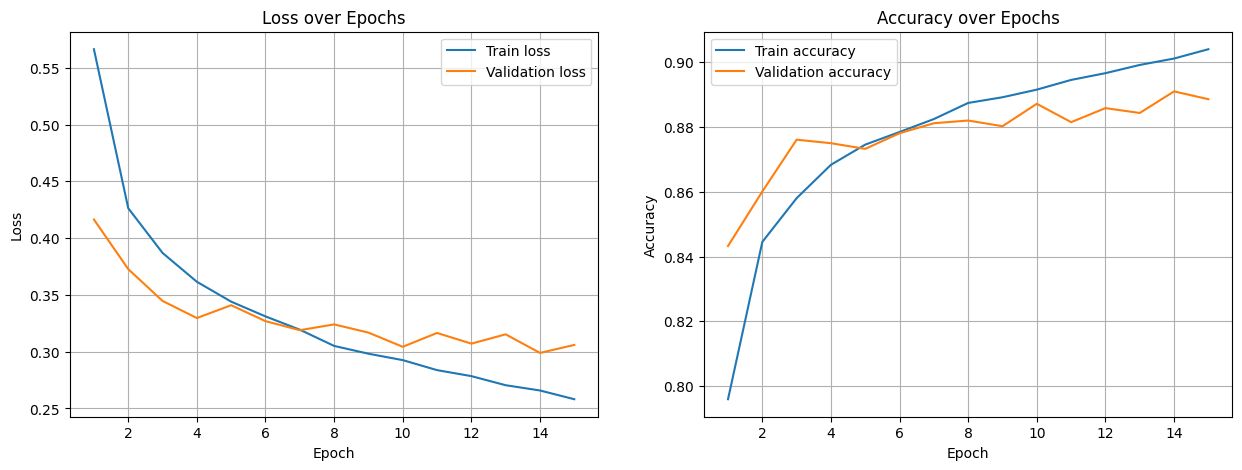

In [11]:
import matplotlib.pyplot as plt

# 1. Plotting the Learning Curves
# We will create a figure with two subplots: one for Loss, one for Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

epochs_range = range(1, len(history['train_loss']) + 1)

# TODO: Plot Train Loss and Validation Loss on the first axis (ax1)
# Use history['train_loss'] and history['val_loss']
ax1.plot(epochs_range, history['train_loss'], label='Train loss')
ax1.plot(epochs_range, history['val_loss'], label='Validation loss')
ax1.set_title('Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# TODO: Plot Train Accuracy and Validation Accuracy on the second axis (ax2)
# Use history['train_acc'] and history['val_acc']
ax2.plot(epochs_range, history['train_acc'], label='Train accuracy')
ax2.plot(epochs_range, history['val_acc'], label='Validation accuracy')
ax2.set_title('Accuracy over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.show()

In [14]:
%pip install scikit-learn

  Using cached scikit_learn-1.6.1-cp39-cp39-win_amd64.whl.metadata (15 kB)
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
Using cached scikit_learn-1.6.1-cp39-cp39-win_amd64.whl (11.2 MB)
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
   ---------------------------------------- 0.0/46.2 MB ? eta -:--:--
   -- ------------------------------------- 3.1/46.2 MB 18.5 MB/s eta 0:00:03
   ----- ---------------------------------- 6.6/46.2 MB 16.8 MB/s eta 0:00:03
   -------- ------------------------------- 10.0/46.2 MB 16.8 MB/s eta 0:00:03
   ------------ --------------------------- 13.9/46.2 MB 17.1 MB/s eta 0:00:02
   ----------------- ---------------------- 20.2/46.2 MB 19.9 MB/s eta 0:00:02
   ----------------------- ---------------- 27.3/46.2 MB 22.4 MB/s eta 0:00:01
   ------------------------------ --------- 35.1/46.2 MB 24.5 MB/s eta 0:00:01
   ------------------------------------ --- 41.7/46.2 


--- FINAL TEST EVALUATION ---
Final Test Loss: 0.3419
Final Test Accuracy: 88.12%
              precision    recall  f1-score   support

 T-shirt/top      0.801     0.877     0.837      1000
     Trouser      0.989     0.971     0.980      1000
    Pullover      0.760     0.833     0.795      1000
       Dress      0.898     0.870     0.884      1000
        Coat      0.807     0.819     0.813      1000
      Sandal      0.941     0.968     0.954      1000
       Shirt      0.757     0.640     0.694      1000
     Sneaker      0.907     0.951     0.928      1000
         Bag      0.976     0.966     0.971      1000
  Ankle boot      0.986     0.917     0.950      1000

    accuracy                          0.881     10000
   macro avg      0.882     0.881     0.881     10000
weighted avg      0.882     0.881     0.881     10000



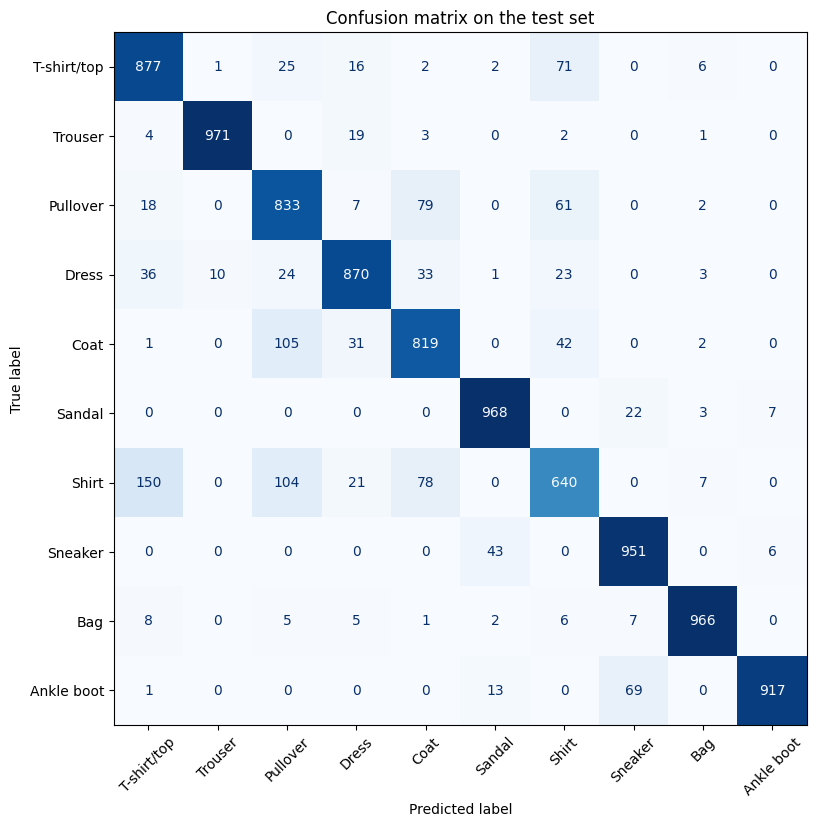

In [15]:
print("\n--- FINAL TEST EVALUATION ---")

# TODO: Evaluate the model on the test_loader using your evaluate function
test_loss, test_acc = validation(model, test_loader, criterion, device)

print(f"Final Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {test_acc * 100:.2f}%")

# TODO: Implement additional evaluation metrics and visualizations
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Collect every prediction and every true label of the test set
all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs.to(device))
        all_preds.append(outputs.argmax(dim=1).cpu())
        all_labels.append(labels)
all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

# Per-class precision, recall and F1
print(classification_report(all_labels, all_preds, target_names=classes, digits=3))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
ax.set_title('Confusion matrix on the test set')
plt.show()

## Part 6: Checkpointing, Monitoring, and Early Stopping

Training for a fixed number of epochs blindly often leads to overfitting, and relying solely on final metrics makes debugging difficult. A robust Deep Learning pipeline solves these issues using three techniques:

   - Early Stopping: Halting the training process automatically when the validation loss stops improving for a set number of epochs (the patience).

   - Checkpointing: Saving the model's weights (state_dict) exactly when it achieves its best validation score, rather than keeping the overfitted weights from the final epoch.

   - Live Monitoring: Dynamically tracking loss curves, gradient flow, and sample predictions during training to immediately diagnose vanishing gradients or persistent misclassifications.

Complete the EarlyStopping class and the diagnostic helper functions. Then, integrate them into a final, comprehensive training loop that updates a live visualization dashboard at the end of every epoch.

In [ ]:
# 1. Initialization
ultimate_model = MLP(hidden_sizes=[256, 128], dropout_rate=0.3).to(device)
optimizer = torch.optim.Adam(ultimate_model.parameters(), lr=1e-3)
criterion = torch.nn.CrossEntropyLoss()

# Initialize Early Stopping (Patience of 4 epochs)
early_stopper = EarlyStopping(patience=4, path='best_ultimate_model.pth')

epochs = 30
live_history = {'train_loss': [], 'val_loss': []}

# 2. The Loop
for epoch in range(epochs):
    # Train and Evaluate using functions from Part 4
    train_loss, train_acc = train_epoch(ultimate_model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(ultimate_model, val_loader, criterion, device)

    live_history['train_loss'].append(train_loss)
    live_history['val_loss'].append(val_loss)

    # --- UPDATE DASHBOARD ---
    # TODO: Call update_dashboard(...)

    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    # --- EARLY STOPPING CHECK ---
    # TODO: Call early_stopper with val_loss and ultimate_model
    # ...

    # TODO: Break the loop if early_stopper.early_stop is True
    # ...

# 3. Load the Best Checkpoint
print("Training finished! Loading the best weights...")
# TODO: Use torch.load to get the best weights, then ultimate_model.load_state_dict()
# ...

# Final test evaluation
final_test_loss, final_test_acc = evaluate(ultimate_model, test_loader, criterion, device)
print(f"Best Test Accuracy: {final_test_acc * 100:.2f}%")

## Part 7: Bag of Tricks and Beyond

To squeeze out the last percentages of accuracy and effectively combat overfitting on complex datasets, deep learning practitioners rely on a standard "bag of tricks". In this section, we will upgrade our model and training pipeline using four industry-standard techniques:

- Batch Normalization (nn.BatchNorm1d): Normalizes the activations of the previous layer for each batch.
    - Pro-tip: The standard order of operations is typically: Linear $\rightarrow$ BatchNorm $\rightarrow$ Activation (ReLU) $\rightarrow$ Dropout.
- Dropout (nn.Dropout): Randomly zeroes out a fraction of neurons during training.
- L2 Regularization / Weight Decay: Penalizes excessively large weights in the network. In PyTorch, this isn't added to the loss function manually; it is handled directly by the Optimizer via the weight_decay parameter.
- Learning Rate Scheduling (ReduceLROnPlateau): Keeping the same learning rate throughout training isn't optimal. A high learning rate is good at the start to explore, but a smaller one is needed at the end to converge to the exact minimum. Schedulers automatically reduce the learning rate when the validation metrics stop improving.

Incorporate these techniques into your model and training loop. Experiment with different hyperparameters (dropout rates, weight decay values, learning rate schedules) to observe their effects on training dynamics and final performance.

This is the time to get creative! Check that you have truly understood the concepts listed in your learning sheet, and try to implement them in your model. Explore their effects and document your findings!

In [17]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

class EarlyStopping:
    """
    EarlyStopping class implementing early stopping logic to terminate training
    when validation performance degrades or plateaus. Also provides checkpointing
    functionality to save the best model during training.

    :ivar patience: (int) Number of epochs to wait for improvement in validation loss
        before stopping.
    :ivar min_delta: (float) Minimum change in validation loss to qualify as an improvement.
    :ivar path: (str) File path where the best model checkpoint is saved.
    :ivar counter: (int) Counter for non-improving epochs.
    :ivar best_loss: (float) Best validation loss observed so far.
    :ivar early_stop: (bool) Flag indicating whether early stopping has been triggered.
    :type early_stop: bool
    """
    def __init__(self, patience=5, min_delta=0.0, path='best_model.pth'):
        self.patience = patience
        self.min_delta = min_delta
        self.path = path
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss, model):
        """
        Manage the early stopping and model checkpointing mechanism during training.

        :param val_loss: (float) The validation loss of the current epoch.
        :param model: (torch.nn.Module) Current state of the model to potentially checkpoint.
        :return: None; breaks loop if early_stop is set to True.
        """
        # TODO: Implement the Early Stopping and Checkpointing logic
        # 1. If self.best_loss is None: set it to val_loss and call self.save_checkpoint(model)
        if self.best_loss is None:
            self.best_loss = val_loss
            self.save_checkpoint(model)
        # 2. Else if val_loss > self.best_loss - self.min_delta:
        #      Increment counter. If counter >= patience, set self.early_stop = True
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        # 3. Else (loss improved): update best_loss, reset counter to 0, save_checkpoint(model)
        else:
            self.best_loss = val_loss
            self.counter = 0
            self.save_checkpoint(model)

    def save_checkpoint(self, model):
        """
        Saves the model's state dictionary to the specified file path.

        :param model: (torch.nn.Module) Current state of the model to checkpoint.
        :return: None
        """
        # TODO: Use torch.save to save model.state_dict() to self.path
        torch.save(model.state_dict(), self.path)


def plot_grad_flow(named_parameters, ax):
    """
    Plots the gradient flow mean absolute values for the provided named
    parameters onto the specified axes. This visualization helps in
    understanding the gradient fluctuations or potential issues during backpropagation
    for different layers of the neural network.

    :param named_parameters:
        Iterator containing tuples of parameter names and corresponding
        tensor objects. Each tuple represents a parameter layer's name
        and its associated tensor from a model.
    :param ax:
        The axis object from a matplotlib figure where the gradient
        flow visualization will be drawn.

    :return:
        None
    """
    ave_grads = []
    layers = []

    for n, p in named_parameters:
        if (p.requires_grad) and ("bias" not in n) and (p.grad is not None):
            layers.append(n)
            # TODO: Compute the mean of the absolute values of the gradients (p.grad)
            grad_mean = p.grad.abs().mean().item()
            ave_grads.append(grad_mean)

    ax.bar(np.arange(len(ave_grads)), ave_grads, alpha=0.5, color="teal")
    ax.set_xticks(np.arange(len(ave_grads)))
    ax.set_xticklabels(layers, rotation=45, ha="right")
    ax.set_title("Gradient Flow (Mean Abs)")
    ax.set_ylabel("Magnitude")

def update_dashboard(history, model, val_loader, device, epoch):
    """
    Updates a dashboard with real-time visualizations that include learning curves,
    gradient flow, and live sample predictions.

    :param history: (dict) Dictionary containing training and validation loss.
                    Keys must include 'train_loss' and 'val_loss'.
    :param model: (torch.nn.Module) The trained PyTorch model whose gradients and predictions
                  will be visualized.
    :param val_loader: (torch.utils.data.Dataloader) A PyTorch DataLoader for the validation dataset. Provides
                       samples for live prediction visualization.
    :param device: (torch.device) The computational device on which the tensors are processed,
                   typically 'cpu' or 'cuda'.
    :param epoch: (int) The current epoch number during training.
    :return: None; updates the visualization output.
    """
    clear_output(wait=True)
    fig = plt.figure(figsize=(18, 5))

    # 1. Learning Curves
    ax1 = fig.add_subplot(1, 3, 1)
    ax1.plot(history['train_loss'], label='Train Loss')
    ax1.plot(history['val_loss'], label='Val Loss')
    ax1.set_title(f"Loss (Epoch {epoch})")
    ax1.legend()

    # 2. Gradient Flow
    ax2 = fig.add_subplot(1, 3, 2)
    # TODO: Call plot_grad_flow with model.named_parameters() and ax2
    plot_grad_flow(model.named_parameters(), ax2)

    # 3. Live Sample Prediction
    ax3 = fig.add_subplot(1, 3, 3)
    ax3.axis('off')

    # Get a single batch, make a prediction, and plot the first image
    model.eval()
    inputs, labels = next(iter(val_loader))
    inputs, labels = inputs.to(device), labels.to(device)
    with torch.no_grad():
        outputs = model(inputs)
        preds = torch.argmax(outputs, dim=1)

    img = inputs[0].cpu().squeeze() * 0.5 + 0.5 # Denormalize
    ax3.imshow(img, cmap='gray')
    color = 'green' if preds[0] == labels[0] else 'red'
    ax3.set_title(f"Pred: {preds[0].item()} | True: {labels[0].item()}", color=color, weight='bold')

    plt.tight_layout()
    plt.show()

Baseline | epoch 1/10 | train 0.5702 / 0.7943 | val 0.4197 / 0.8441
Baseline | epoch 2/10 | train 0.4270 / 0.8446 | val 0.3798 / 0.8537
Baseline | epoch 3/10 | train 0.3858 / 0.8586 | val 0.3861 / 0.8558
Baseline | epoch 4/10 | train 0.3636 / 0.8655 | val 0.3566 / 0.8657
Baseline | epoch 5/10 | train 0.3443 / 0.8736 | val 0.3355 / 0.8721
Baseline | epoch 6/10 | train 0.3333 / 0.8768 | val 0.3411 / 0.8695
Baseline | epoch 7/10 | train 0.3204 / 0.8812 | val 0.3279 / 0.8771
Baseline | epoch 8/10 | train 0.3092 / 0.8855 | val 0.3188 / 0.8838
Baseline | epoch 9/10 | train 0.3005 / 0.8895 | val 0.3142 / 0.8851
Baseline | epoch 10/10 | train 0.2903 / 0.8914 | val 0.3222 / 0.8826
Batch norm | epoch 1/10 | train 0.5206 / 0.8199 | val 0.3633 / 0.8644
Batch norm | epoch 2/10 | train 0.3905 / 0.8570 | val 0.3305 / 0.8762
Batch norm | epoch 3/10 | train 0.3553 / 0.8702 | val 0.3270 / 0.8800
Batch norm | epoch 4/10 | train 0.3301 / 0.8771 | val 0.3217 / 0.8822
Batch norm | epoch 5/10 | train 0.3139 

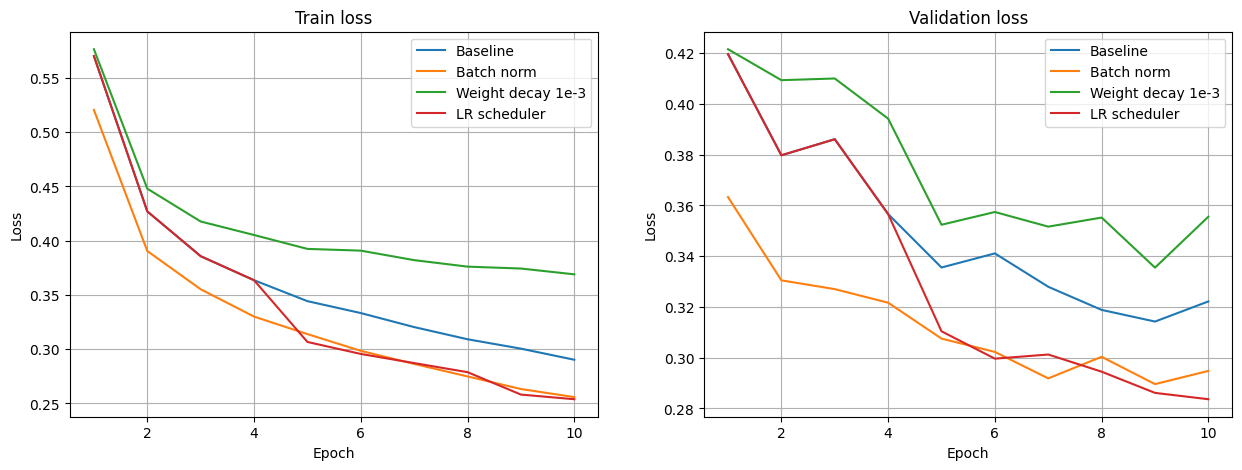

Run                  Train acc   Val acc     Gap  Best val loss
Baseline                0.8914    0.8826  0.0088         0.3142
Batch norm              0.9042    0.8925  0.0117         0.2896
Weight decay 1e-3       0.8658    0.8687 -0.0028         0.3355
LR scheduler            0.9067    0.8948  0.0119         0.2836


In [18]:
# EXPERIMENTS: batch normalization, weight decay, LR scheduler

criterion = nn.CrossEntropyLoss()

def make_model(use_bn=False, dropout_rate=0.2):
    # Same architecture as MLP(hidden_sizes=[256, 128]), with optional batch norm
    layers = [nn.Flatten()]
    in_features = 784
    for h in [256, 128]:
        layers.append(nn.Linear(in_features, h))
        if use_bn:
            layers.append(nn.BatchNorm1d(h))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(dropout_rate))
        in_features = h
    layers.append(nn.Linear(in_features, 10))
    return nn.Sequential(*layers).to(device)

def run_experiment(name, use_bn=False, weight_decay=0.0, use_scheduler=False, epochs=10):
    torch.manual_seed(0)  # same starting weights for every run
    net = make_model(use_bn)
    opt = optim.Adam(net.parameters(), lr=1e-3, weight_decay=weight_decay)
    sched = optim.lr_scheduler.StepLR(opt, step_size=4, gamma=0.3) if use_scheduler else None
    h = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for epoch in range(epochs):
        tl, ta = train_epoch(net, train_loader, criterion, opt, device)
        vl, va = validation(net, val_loader, criterion, device)
        if sched is not None:
            sched.step()
        h['train_loss'].append(tl); h['train_acc'].append(ta)
        h['val_loss'].append(vl);   h['val_acc'].append(va)
        print(f"{name} | epoch {epoch+1}/{epochs} | "
              f"train {tl:.4f} / {ta:.4f} | val {vl:.4f} / {va:.4f}")
    return h

results = {
    'Baseline':          run_experiment('Baseline'),
    'Batch norm':        run_experiment('Batch norm', use_bn=True),
    'Weight decay 1e-3': run_experiment('Weight decay 1e-3', weight_decay=1e-3),
    'LR scheduler':      run_experiment('LR scheduler', use_scheduler=True),
}

# Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
x = range(1, 11)
for name, h in results.items():
    ax1.plot(x, h['train_loss'], label=name)
    ax2.plot(x, h['val_loss'], label=name)
ax1.set_title('Train loss'); ax2.set_title('Validation loss')
for ax in (ax1, ax2):
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss'); ax.legend(); ax.grid(True)
plt.show()

# Summary
print(f"{'Run':<20}{'Train acc':>10}{'Val acc':>10}{'Gap':>8}{'Best val loss':>15}")
for name, h in results.items():
    gap = h['train_acc'][-1] - h['val_acc'][-1]
    print(f"{name:<20}{h['train_acc'][-1]:>10.4f}{h['val_acc'][-1]:>10.4f}"
          f"{gap:>8.4f}{min(h['val_loss']):>15.4f}")